<a href="https://colab.research.google.com/github/loudamn78-gif/smartstay-ai/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. فهم المشكلة

**١. من العميل؟ وما مشكلته؟ وكم تكلّفه؟**
العميل هو مالك جديد على منصة تأجير شقق قصيرة في نيويورك. المنصة فيها قرابة 49 ألف إعلان (48,895 في الداتا)، وسعر الليلة فيها من 10 إلى 10,000 دولار. مشكلته أنه يسعّر شقته بالتخمين: لو غلّى السعر ما يحجز عنده أحد، ولو رخّصه يخسر من دخله في كل ليلة.

**٢. ما الـ Target؟ وما نوعه؟**
الـ Target هو `price` (سعر الليلة بالدولار). نوعه **رقم** (يظهر في `dtypes` كـ int64)، مثل 149 و225 و80 في أول صفوف الداتا. ولأنه رقم، فالمشكلة هي توقّع رقم وليست تصنيفًا.

**٣. من سيستخدم منتجك؟ وماذا يحتاج أن يرى أول ما يفتحه؟**
سيستخدمه المالك الجديد. أول ما يفتح الأداة يدخل منطقة الشقة ونوع الغرفة، ويحتاج يرى مباشرة السعر المقترح لليلة الواحدة، مع شقق مشابهة لشقته وأسعارها، حتى يقرر بناءً على بيانات وليس تخمينًا.

**٤. ثلاثة أسئلة فرعية ستساعدني في الإجابة عن سؤال العميل:**
1. كيف يختلف سعر الليلة بين المناطق (`neighbourhood_group`)؟
2. كيف يختلف السعر بين أنواع الغرف (`room_type`)؟
3. هل للحد الأدنى لعدد الليالي (`minimum_nights`) أو عدد أيام التوفر خلال السنة (`availability_365`) علاقة بالسعر؟

##2. اول نظرة

## الاستيراد وقراءة الداتا

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
df = pd.read_csv("data/raw.csv")

In [90]:
print("الصفوف والأعمدة:", df.shape)

الصفوف والأعمدة: (48895, 16)


## **:عينة**

In [91]:
display(df.head())

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## الانواع:

In [92]:
display(df.dtypes)

,0
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


## النقص:

In [93]:
display(df.isna().sum().sort_values(ascending=False))

,0
last_review,10052
reviews_per_month,10052
host_name,21
name,16
neighbourhood_group,0
neighbourhood,0
id,0
host_id,0
longitude,0
latitude,0


## التكرار:

In [94]:
print("الصفوف المكررة:", df.duplicated().sum())
print("id مكرر:", df["id"].duplicated().sum())

الصفوف المكررة: 0
id مكرر: 0


## الاحصائيات:

In [95]:
display(df.describe())

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


## القيم الفريدة في الاعمدة النصية:

In [96]:
for col in df.select_dtypes(include="object").columns:
    print(f"{col}: {df[col].nunique()} قيمة فريدة -> {list(df[col].dropna().unique()[:5])}")

name: 47905 قيمة فريدة -> ['Clean & quiet apt home by the park', 'Skylit Midtown Castle', 'THE VILLAGE OF HARLEM....NEW YORK !', 'Cozy Entire Floor of Brownstone', 'Entire Apt: Spacious Studio/Loft by central park']
host_name: 11452 قيمة فريدة -> ['John', 'Jennifer', 'Elisabeth', 'LisaRoxanne', 'Laura']
neighbourhood_group: 5 قيمة فريدة -> ['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx']
neighbourhood: 221 قيمة فريدة -> ['Kensington', 'Midtown', 'Harlem', 'Clinton Hill', 'East Harlem']
room_type: 3 قيمة فريدة -> ['Private room', 'Entire home/apt', 'Shared room']
last_review: 1764 قيمة فريدة -> ['2018-10-19', '2019-05-21', '2019-07-05', '2018-11-19', '2019-06-22']


**ملاحظاتي من أول نظرة:**
- **الحجم:** 48,895 صف و16 عمود، وما فيه صفوف مكررة ولا `id` مكرر (0).
- **الأنواع:** معظم الأعمدة صحيحة (أرقام للأرقام ونصوص للنصوص)، لكن `last_review` مخزّن كنص (object) وليس تاريخًا، وشكله `dd-mm-yyyy`.
- **النقص:** `last_review` و`reviews_per_month` ناقصان في 10,052 صف لكل منهما (نفس العدد)، و`host_name` ناقص في 21 صف، و`name` في 16 صف.
- **الـ Target (`price`):** أقل قيمة 0، ووسيطه 106 دولار، ومتوسطه 152.7، وأعلى قيمة 10,000. المتوسط أكبر من الوسيط، فالأسعار العالية جدًا تسحبه للأعلى.
- **`minimum_nights`:** وسيطه 3 ليالٍ، لكن أعلى قيمة 1,250 ليلة (أكثر من 3 سنوات).
- **الأعمدة النصية:** 5 مناطق (`neighbourhood_group`)، و221 حيًّا، و3 أنواع غرف.
- **الإحداثيات:** كلها ضمن نطاق نيويورك.

## 3.EDA

### الرسمة 1: توزيع الـ Target (price)

count    48895.0
mean       152.7
std        240.2
min          0.0
25%         69.0
50%        106.0
75%        175.0
max      10000.0
Name: price, dtype: float64
99%: 799.0


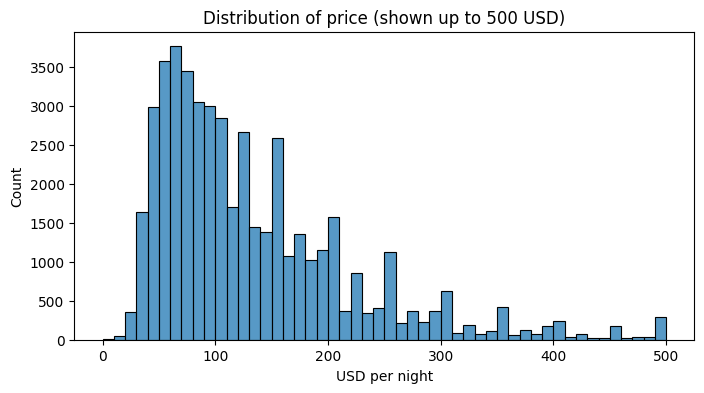

In [97]:
print(df["price"].describe().round(1))
print("99%:", df["price"].quantile(0.99))

# للعرض فقط: نقص الرسم عند 500 دولار حتى يظهر الشكل (لا نعدّل df)
plt.figure(figsize=(8, 4))
sns.histplot(df.loc[df["price"] <= 500, "price"], bins=50)
plt.title("Distribution of price (shown up to 500 USD)")
plt.xlabel("USD per night")
plt.show()

**الجملة:** وسيط سعر الليلة 106 دولار بينما المتوسط 152.7، لأن قلّة من الإعلانات غالية جدًا (أعلى سعر 10,000 دولار، و99% من الإعلانات أقل من 799 دولار) تسحب المتوسط للأعلى، وأغلب الأسعار تتركز بين 50 و150 دولار تقريبًا.

### الرسمة 2: السعر حسب المنطقة

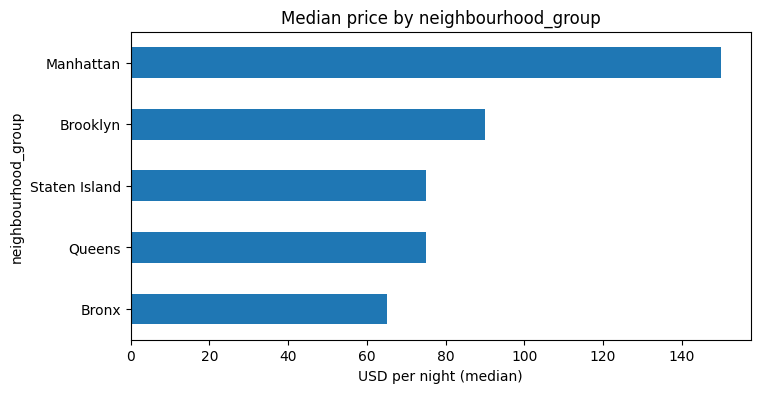

neighbourhood_group
Bronx             65.0
Queens            75.0
Staten Island     75.0
Brooklyn          90.0
Manhattan        150.0
Name: price, dtype: float64


In [98]:
med_area = df.groupby("neighbourhood_group")["price"].median().sort_values()
med_area.plot(kind="barh", figsize=(8, 4), title="Median price by neighbourhood_group")
plt.xlabel("USD per night (median)")
plt.show()
print(med_area)

**الجملة:** Manhattan الأغلى بوسيط 150 دولار لليلة، وBronx الأرخص بـ65 دولار، أي فرق 85 دولار (أكثر من الضعف)، وBrooklyn في الوسط بـ90 دولار، وQueens وStaten Island متساويتان عند 75 دولار.

### الرسمة 3: السعر حسب نوع الغرفة

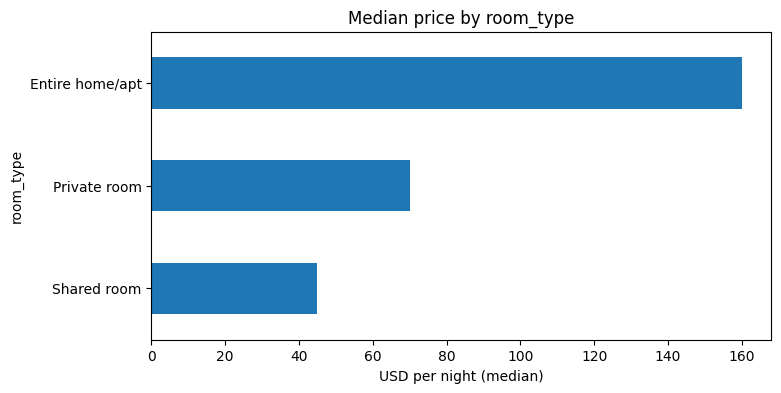

room_type
Shared room         45.0
Private room        70.0
Entire home/apt    160.0
Name: price, dtype: float64


In [99]:
med_room = df.groupby("room_type")["price"].median().sort_values()
med_room.plot(kind="barh", figsize=(8, 4), title="Median price by room_type")
plt.xlabel("USD per night (median)")
plt.show()
print(med_room)

**أهم عمودين في رأيي وعلاقتهما بالـ Target:**
1. `room_type`: لأن وسيط السعر يتغير من 45 دولار (غرفة مشتركة) إلى 160 دولار (شقة كاملة)، أي أكثر من 3 أضعاف.
2. `neighbourhood_group`: لأن وسيط السعر يتغير من 65 دولار في Bronx إلى 150 دولار في Manhattan، أي أكثر من الضعف.

## 4. مفاجآت الداتا

##1. النقص:

In [100]:
miss = df.isna().sum()
print(miss[miss > 0])
print("last_review و reviews_per_month ناقصان معًا:", int((df["last_review"].isna() & df["reviews_per_month"].isna()).sum()))
print("صفر تقييمات number_of_reviews == 0:", int((df["number_of_reviews"] == 0).sum()))

name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64
last_review و reviews_per_month ناقصان معًا: 10052
صفر تقييمات number_of_reviews == 0: 10052


## 2.ال Target:

In [101]:
print("price == 0:", int((df["price"] == 0).sum()))
print("price > 1000:", int((df["price"] > 1000).sum()), "| max:", df["price"].max())
print(df.loc[df["price"] >= 5000, ["name", "neighbourhood_group", "room_type", "price"]].head(10))

price == 0: 11
price > 1000: 239 | max: 10000
                                      name neighbourhood_group  \
2698   Beautiful 1 Bedroom in Nolita/Soho            Manhattan   
3537    UWS 1BR w/backyard + block from CP           Manhattan   
3720   SuperBowl Penthouse Loft 3,000 sqft           Manhattan   
3774      SUPER BOWL Brooklyn Duplex Apt!!            Brooklyn   
4345      NearWilliamsburg bridge 11211 BK            Brooklyn   
4377                         Film Location            Brooklyn   
6530                    Spanish Harlem Apt           Manhattan   
9151   Furnished room in Astoria apartment              Queens   
12342  Quiet, Clean, Lit @ LES & Chinatown           Manhattan   
15560   Luxury townhouse Greenwich Village           Manhattan   

             room_type  price  
2698   Entire home/apt   5000  
3537   Entire home/apt   6000  
3720   Entire home/apt   5250  
3774   Entire home/apt   6500  
4345      Private room   5000  
4377   Entire home/apt   8000  
653

## 3. الحد الادنى لليالي:

In [102]:
print("minimum_nights > 30:", int((df["minimum_nights"] > 30).sum()))
print("minimum_nights > 365:", int((df["minimum_nights"] > 365).sum()), "| max:", df["minimum_nights"].max())

minimum_nights > 30: 747
minimum_nights > 365: 14 | max: 1250


##4.التوفر:

In [103]:
print("availability_365 == 0:", int((df["availability_365"] == 0).sum()))

availability_365 == 0: 17533


##5.نوع التاريخ:

In [104]:
print(df["last_review"].dtype, "| مثال:", df["last_review"].dropna().iloc[0])

object | مثال: 2018-10-19


##6. الاحداثيات:

In [105]:
out = ~df["latitude"].between(40.4, 41.0) | ~df["longitude"].between(-74.3, -73.7)
print("خارج نطاق نيويورك:", int(out.sum()))

خارج نطاق نيويورك: 0


##7.الفئات:

In [106]:
print(df["neighbourhood_group"].value_counts(dropna=False).to_dict())
print(df["room_type"].value_counts(dropna=False).to_dict())
print("neighbourhood فريد:", df["neighbourhood"].nunique())

{'Manhattan': 21661, 'Brooklyn': 20104, 'Queens': 5666, 'Bronx': 1091, 'Staten Island': 373}
{'Entire home/apt': 25409, 'Private room': 22326, 'Shared room': 1160}
neighbourhood فريد: 221


### جدول المفاجآت

| المشكلة | العمود | كم صفًا؟ | قراري المبدئي |
|---|---|---|---|
| سعر الليلة صفر (قيمة مستحيلة) | `price` | 11 | أستبعدها قبل بناء الأداة، لأن شقة بسعر 0 غير منطقية |
| أسعار متطرفة جدًا (أكثر من 1000 دولار، وأعلى سعر 10,000) | `price` | 239 | أراجعها غدًا: بعضها يبدو غير واقعي (غرفة خاصة بـ10,000 دولار)، فأغلب الظن أستبعدها أو أحدّ منها |
| حد أدنى للإقامة أكثر من سنة (أعلى قيمة 1,250 ليلة) | `minimum_nights` | 14 | أستبعدها، لأنها لا تناسب التأجير القصير |
| حد أدنى أكثر من 30 ليلة (إيجار شهري وليس قصيرًا) | `minimum_nights` | 747 | أقرر غدًا هل أبقيها أو أستبعدها، حسب تأثيرها على السعر |
| نقص في تاريخ آخر تقييم ومتوسط التقييمات الشهري | `last_review` و`reviews_per_month` | 10,052 لكل منهما | ليس خطأ: نفس عدد الإعلانات بصفر تقييمات (10,052)، فأتركه فارغًا لـ`last_review` وأعوّض `reviews_per_month` بصفر |
| تاريخ مخزّن كنص بدل تاريخ | `last_review` | 38,843 (غير الناقصة) | أحوّله إلى تاريخ بصيغة يوم-شهر-سنة |
| غير متاح طوال السنة (availability = 0) | `availability_365` | 17,533 | أبقيها لكن أراجع علاقتها بالسعر، لأن قد تكون إعلانات موقوفة |
| اسم الإعلان أو المضيف ناقص | `name` و`host_name` | 16 و21 | لا أحتاجهما في تسعير الشقة، فأتجاهلهما |
**فحوصات أخرى طلعت سليمة:**
- **الإحداثيات (`latitude` و`longitude`):** كلها داخل نطاق نيويورك (0 خارج النطاق).
- **الفئات:** `neighbourhood_group` فيها 5 مناطق و`room_type` فيها 3 أنواع فقط بدون أخطاء كتابة أو قيم غريبة، و`neighbourhood` فيها 221 قيمة فريدة.
- **التكرار:** 0 صفوف مكررة و0 `id` مكرر.

## 5. التنظيف
اعمل على نسخة `clean` من الداتا، واوثق كل قرار في Decision Log.

##خلية1:الاقنعة(على الداتا الاصلية)

In [107]:
m_zero = df["price"] == 0
m_high = df["price"] > 1000
m_nights = df["minimum_nights"] > 365

for name, m in [("price == 0", m_zero), ("price > 1000", m_high), ("minimum_nights > 365", m_nights)]:
    print(f"{name}: {m.sum()} ({m.mean()*100:.2f}%)")
print("المجموع بدون تكرار:", (m_zero | m_high | m_nights).sum())
print("أقل سعر أكبر من صفر:", df.loc[df["price"] > 0, "price"].min())
print("price > 1000 هو فوق المئين 99.5:", df["price"].quantile(0.995))

price == 0: 11 (0.02%)
price > 1000: 239 (0.49%)
minimum_nights > 365: 14 (0.03%)
المجموع بدون تكرار: 264
أقل سعر أكبر من صفر: 10
price > 1000 هو فوق المئين 99.5: 1000.0


##2:دليل اضافي على الاسعار المتطرفة

In [108]:
print("بدون تقييمات داخل price>1000:", round((df.loc[m_high, "number_of_reviews"] == 0).mean()*100, 1), "% | في كل الإعلانات:", round((df["number_of_reviews"] == 0).mean()*100, 1), "%")
print("المتوسط قبل:", round(df["price"].mean(), 1), "| بعد استبعاد price>1000 فقط:", round(df.loc[~m_high, "price"].mean(), 1))

بدون تقييمات داخل price>1000: 55.2 % | في كل الإعلانات: 20.6 %
المتوسط قبل: 152.7 | بعد استبعاد price>1000 فقط: 141.3


##3: خلية الحذف

In [109]:
clean = df[~(m_zero | m_high | m_nights)].copy()
print("الصفوف المحذوفة:", len(df) - len(clean), f"({(len(df)-len(clean))/len(df)*100:.2f}%)")

الصفوف المحذوفة: 264 (0.54%)


##4:تحويل last_review الى تاريخ

In [110]:
clean["last_review"] = pd.to_datetime(clean["last_review"], format="%Y-%m-%d")
print(clean["last_review"].dtype, "| ناقص:", clean["last_review"].isna().sum())

datetime64[ns] | ناقص: 9911


##5:reviews_per_month(بدون استخدام ال Target)

In [111]:
miss = clean["reviews_per_month"].isna()
print("ناقص:", miss.sum(), "| منها عدد تقييماتها صفر:", (clean.loc[miss, "number_of_reviews"] == 0).sum())
print("كل من تقييماته صفر ناقص؟", clean.loc[clean["number_of_reviews"] == 0, "reviews_per_month"].isna().all())
clean["reviews_per_month"] = clean["reviews_per_month"].fillna(0)

ناقص: 9911 | منها عدد تقييماتها صفر: 9911
كل من تقييماته صفر ناقص؟ True


##6:host-nameوname

In [112]:
print("name ناقص:", clean["name"].isna().sum(), "| host_name ناقص:", clean["host_name"].isna().sum())
clean["name"] = clean["name"].fillna("Unknown")
clean["host_name"] = clean["host_name"].fillna("Unknown")

name ناقص: 15 | host_name ناقص: 21


##7:توثيق ماابقيته (للارقام فقط)

In [113]:
n_mid = ((clean["minimum_nights"] > 30) & (clean["minimum_nights"] <= 365)).sum()
n_av0 = (clean["availability_365"] == 0).sum()
print("minimum_nights بين 31 و365:", n_mid, f"({n_mid/len(clean)*100:.1f}%)")
print("availability_365 == 0:", n_av0, f"({n_av0/len(clean)*100:.1f}%)")

minimum_nights بين 31 و365: 707 (1.5%)
availability_365 == 0: 17463 (35.9%)


##8:فحص نهائي وحفظ

In [114]:
print("الشكل بعد التنظيف:", clean.shape)
print(clean.isna().sum()[lambda s: s > 0])
print(clean["price"].describe().round(1))
clean.to_csv("data/clean.csv", index=False)

الشكل بعد التنظيف: (48631, 16)
last_review    9911
dtype: int64
count    48631.0
mean       141.3
std        116.7
min         10.0
25%         69.0
50%        105.0
75%        175.0
max       1000.0
Name: price, dtype: float64


### Decision Log

| المشكلة | القرار | السبب بالرقم | الصفوف المتأثرة |
|---|---|---|---|
| سعر الليلة صفر | حذف الصفوف | 11 إعلانًا (0.02%)، وأقل سعر فوق الصفر 10 دولار، وهو أدنى سعر في وصف المنصة، فالصفر غير منطقي | 11 |
| أسعار متطرفة (أكثر من 1000 دولار) | حذف الصفوف | 239 إعلانًا (0.49%) فوق المئين 99.5؛ 55.2% منها بدون تقييمات مقابل 20.6% في كل الإعلانات؛ وبعد حذفها نزل المتوسط من 152.7 إلى 141.3 | 239 |
| حد أدنى للإقامة أكثر من 365 ليلة | حذف الصفوف | 14 إعلانًا (0.03%)، وأعلى قيمة 1,250 ليلة (أكثر من 3 سنوات) وهذا ليس إيجارًا قصيرًا | 14 |
| حد أدنى بين 31 و365 ليلة | إبقاء بدون تغيير | 707 إعلانات (1.5%) إيجار شهري حقيقي وليس خطأ، وتظهره فئات الإقامة في القسم 6 | 707 (0 محذوف) |
| `last_review` مخزّن كنص | تحويله إلى تاريخ (سنة-شهر-يوم) | قُرئت 38,720 قيمة كلها بدون خطأ، والعمود صار datetime | 38,720 |
| `reviews_per_month` ناقص | ملؤه بـ 0 | 9,911 صفًا ناقصًا، وكلها عدد تقييماتها 0 (تطابق تام: True)، فلا تقييمات تعني معدلًا صفرًا؛ ولم أستخدم الـ Target | 9,911 |
| `last_review` ناقص | إبقاؤه فارغًا | نفس الصفوف (20.4% من 48,631): لا يوجد تاريخ لإعلان بلا تقييمات، ومعلومة موجود/غير موجود محفوظة في `number_of_reviews = 0` | 9,911 |
| `name` و`host_name` ناقصان | ملؤهما بـ Unknown | 15 و21 صفًا (أقل من 0.05%)؛ لا حذف للصفوف، والعمودان لا يؤثران في السعر وسيُراجعان في القسم 7 | 15 / 21 |
| `availability_365` = 0 | إبقاء بدون تغيير | 17,463 إعلانًا (35.9%) أكثر من أن تُحذف، وليست خطأ (تقويم محجوب أو ممتلئ) | 17,463 (0 محذوف) |

**مجموع المحذوف:** 264 صفًا (0.54%) من 48,895، فبقي 48,631 صفًا.

##feature Engineering

## 6. Feature Engineering
اضيف أعمدة جديدة على نسخة `feat` من الداتا النظيفة، وكل عمود له معنى في مجال تسعير الشقق.

In [115]:
feat = clean.copy()

## 1:العمود distance_to midtown_km

### ليش اضفت العمود 1: distance_to_midtown_km
**لماذا أضفته؟** لأن موقع الشقة يؤثر على سعرها، والإحداثيات (latitude و longitude) بشكلها الخام صعب فهم علاقتها بالسعر. حوّلتها إلى رقم واحد واضح: المسافة بالكيلومتر عن Times Square (وسط Manhattan).

                        median  count
distance_to_midtown_km               
0-2                      180.0   5587
2-5                      150.0  11361
5-10                      95.0  21771
10+                       75.0   9912


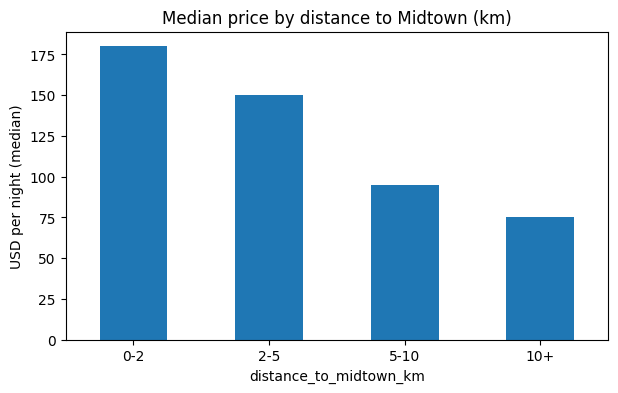

In [116]:
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1
    dlmb = np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

feat["distance_to_midtown_km"] = haversine_km(feat["latitude"], feat["longitude"], 40.7580, -73.9855).round(2)

band = pd.cut(feat["distance_to_midtown_km"], bins=[0, 2, 5, 10, np.inf], labels=["0-2", "2-5", "5-10", "10+"], include_lowest=True)
stats = feat.groupby(band, observed=True)["price"].agg(["median", "count"])
print(stats)

stats["median"].plot(kind="bar", figsize=(7, 4), title="Median price by distance to Midtown (km)")
plt.ylabel("USD per night (median)")
plt.xticks(rotation=0)
plt.show()

**الجملة:** وسيط سعر الليلة 180 دولار للإعلانات القريبة من وسط المدينة (0–2 كم) مقابل 75 دولار للبعيدة (أكثر من 10 كم)، أي أكثر من الضعفين (فرق 105 دولار)، والسعر ينخفض مع كل فئة مسافة، فالقرب من Midtown يرفع السعر.

### العمود 2: is_active_listing
**لماذا أضفته؟** لأن الإعلان اللي عليه تقييم حديث يدل أنه مستخدم فعلًا وسعره مقبول عند الضيوف. استخدمت تاريخ آخر تقييم في الداتا نفسها كتاريخ مرجعي (وليس تاريخ اليوم)، لأن الداتا من 2019، وعدّيت الإعلان نشطًا إذا مرّ على آخر تقييم له 180 يومًا أو أقل. الإعلان بدون تقييمات يعتبر غير نشط.

تاريخ آخر تقييم في الداتا: 2019-07-08
                   median  count
is_active_listing               
0                   109.0  24557
1                   104.0  24074


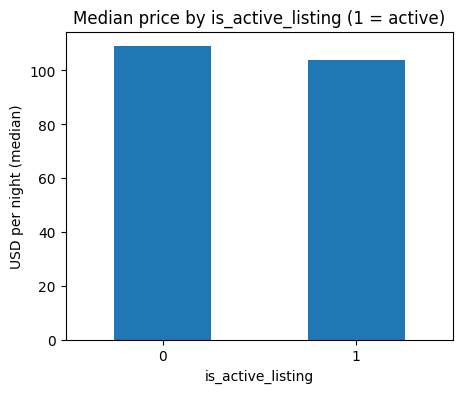

In [117]:
snapshot = feat["last_review"].max()
print("تاريخ آخر تقييم في الداتا:", snapshot.date())

days_since = (snapshot - feat["last_review"]).dt.days
feat["is_active_listing"] = (days_since <= 180).astype(int)

stats = feat.groupby("is_active_listing")["price"].agg(["median", "count"])
print(stats)

stats["median"].plot(kind="bar", figsize=(5, 4), title="Median price by is_active_listing (1 = active)")
plt.ylabel("USD per night (median)")
plt.xticks(rotation=0)
plt.show()

 49.5% من الإعلانات (24,074) نشطة (آخر تقييم خلال 180 يومًا قبل 08-07-2019)، ووسيط سعرها 104 دولار مقابل 109 دولار لغير النشطة، أي فرق 5 دولار فقط، فالنشاط لا يغيّر السعر بشكل واضح.

### العمود 3: stay_type
**لماذا أضفته؟** لأن الحد الأدنى للإقامة (minimum_nights) له قيم كثيرة ومتفاوتة (من 1 إلى 365)، فقسّمته إلى 3 فئات لها معنى: قصيرة (1-6 ليالٍ)، أسبوعية (7-29)، وشهرية فأكثر (30+)، لأن نوع الإقامة يؤثر على سعر الليلة.

                median  count
stay_type                    
short (1-6)      102.0  39328
weekly (7-29)    100.0   4866
monthly+ (30+)   130.0   4437


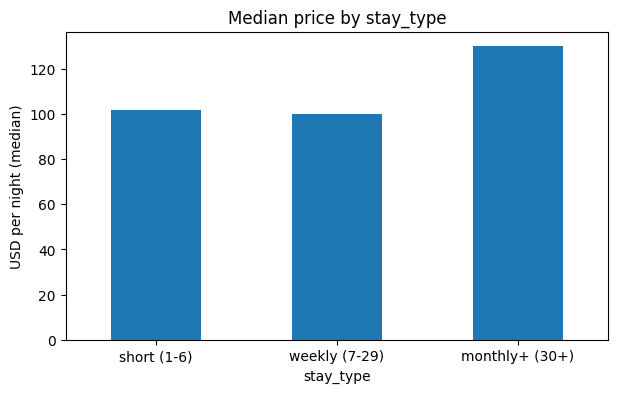

In [118]:
feat["stay_type"] = pd.cut(
    feat["minimum_nights"], bins=[0, 6, 29, np.inf],
    labels=["short (1-6)", "weekly (7-29)", "monthly+ (30+)"],
)

stats = feat.groupby("stay_type", observed=True)["price"].agg(["median", "count"])
print(stats)

stats["median"].plot(kind="bar", figsize=(7, 4), title="Median price by stay_type")
plt.ylabel("USD per night (median)")
plt.xticks(rotation=0)
plt.show()

 وسيط سعر الليلة 102 دولار للإقامة القصيرة (1-6 ليالٍ) و100 دولار للأسبوعية (7-29)، بينما يرتفع إلى 130 دولار للإقامة الشهرية فأكثر (30+)، أي أعلى بـ 28 دولار من القصيرة. والفرق بين القصيرة والأسبوعية صغير (2 دولار فقط)، فتأثير الفئة يظهر في الإقامات الشهرية.

## 7. Feature Selection
الراجع كل عمود: احتفظ به أو احذفة؟ ولماذا؟ وش الرقم اللي يدعم القرار؟

## نظرة على الاعمدة1:

In [119]:
print(feat.shape)
summary = pd.DataFrame({
    "dtype": feat.dtypes.astype(str),
    "unique": feat.nunique(),
    "unique_%": (feat.nunique() / len(feat) * 100).round(1),
})
print(summary)

(48631, 19)
                                         dtype  unique  unique_%
id                                       int64   48631     100.0
name                                    object   47647      98.0
host_id                                  int64   37270      76.6
host_name                               object   11411      23.5
neighbourhood_group                     object       5       0.0
neighbourhood                           object     221       0.5
latitude                               float64   19010      39.1
longitude                              float64   14699      30.2
room_type                               object       3       0.0
price                                    int64     569       1.2
minimum_nights                           int64     100       0.2
number_of_reviews                        int64     394       0.8
last_review                     datetime64[ns]    1762       3.6
reviews_per_month                      float64     938       1.9
calculated_ho

## الارتباط بين الاعمدة الرقمية(للاعمدة المكررة)

                                latitude  longitude  price  minimum_nights  \
latitude                            1.00       0.08   0.06            0.03   
longitude                           0.08       1.00  -0.26           -0.08   
price                               0.06      -0.26   1.00            0.02   
minimum_nights                      0.03      -0.08   0.02            1.00   
number_of_reviews                  -0.02       0.06  -0.06           -0.10   
reviews_per_month                  -0.02       0.14  -0.06           -0.15   
calculated_host_listings_count      0.02      -0.12   0.13            0.17   
availability_365                   -0.01       0.08   0.12            0.17   
distance_to_midtown_km             -0.41       0.54  -0.31           -0.09   
is_active_listing                  -0.03       0.09  -0.03           -0.12   

                                number_of_reviews  reviews_per_month  \
latitude                                    -0.02              -0.02 

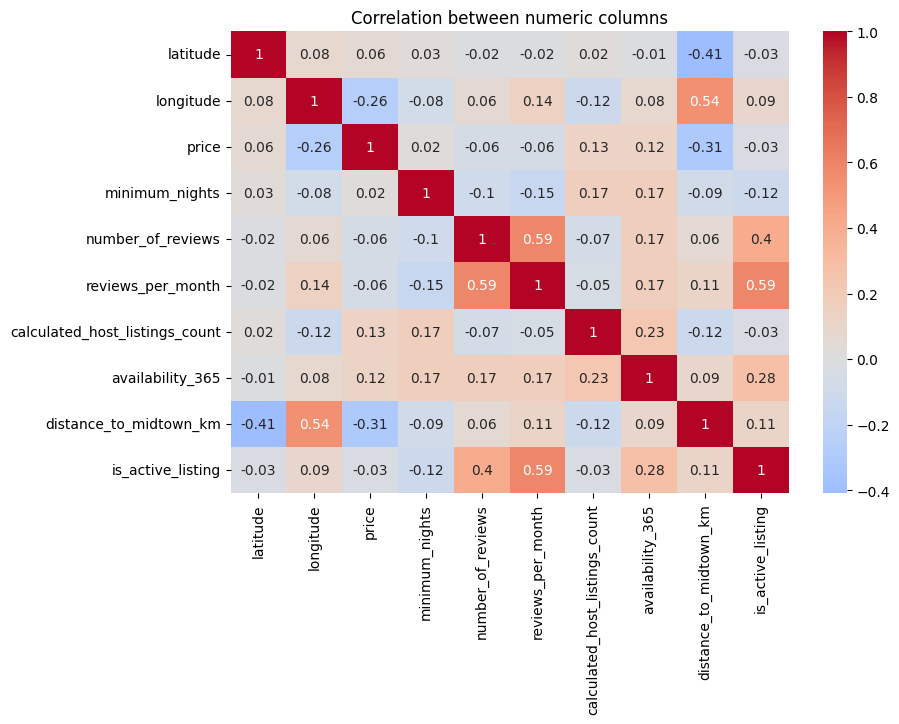

In [120]:
num = feat.select_dtypes(include="number").drop(columns=["id", "host_id"])
corr = num.corr().round(2)
print(corr)

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation between numeric columns")
plt.show()

##رسمة تدعم القرار + ارقام الاحياء

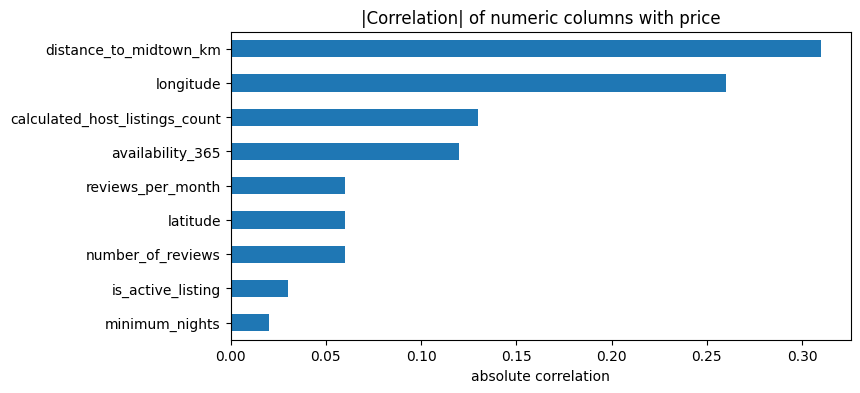

minimum_nights                    0.02
is_active_listing                 0.03
number_of_reviews                 0.06
latitude                          0.06
reviews_per_month                 0.06
availability_365                  0.12
calculated_host_listings_count    0.13
longitude                         0.26
distance_to_midtown_km            0.31
Name: price, dtype: float64
أكبر عدد مناطق لحي واحد: 1
أرخص حي: Washington Heights 72.0 | أغلى حي: Tribeca 282.0
room_type
Entire home/apt    160.0
Private room        70.0
Shared room         45.0
Name: price, dtype: float64
neighbourhood_group
Bronx             65.0
Brooklyn          90.0
Manhattan        149.0
Queens            75.0
Staten Island     75.0
Name: price, dtype: float64


In [121]:
corr_price = corr["price"].drop("price").abs().sort_values()
corr_price.plot(kind="barh", figsize=(8, 4), title="|Correlation| of numeric columns with price")
plt.xlabel("absolute correlation")
plt.show()
print(corr_price.round(2))

# هل كل حي ينتمي لمنطقة واحدة؟
print("أكبر عدد مناطق لحي واحد:", feat.groupby("neighbourhood")["neighbourhood_group"].nunique().max())

# تفاوت أسعار الأحياء داخل Manhattan (أحياء فيها 100 إعلان فأكثر)
man = feat[feat["neighbourhood_group"] == "Manhattan"].groupby("neighbourhood")["price"].agg(["median", "count"])
man = man[man["count"] >= 100]
print("أرخص حي:", man["median"].idxmin(), man["median"].min(), "| أغلى حي:", man["median"].idxmax(), man["median"].max())
print(feat.groupby("room_type")["price"].median())
print(feat.groupby("neighbourhood_group")["price"].median())

 أقوى علاقة مع السعر (بالقيمة المطلقة) لـ `distance_to_midtown_km` (0.31، عكسية: كلما ابتعدت الشقة نقص السعر) ثم `longitude` (0.26، عكسية أيضًا)، وباقي الأعمدة الرقمية أقل من 0.13، فاحتفظت بالأعمدة اللي لها أثر واضح وحذفت المعرّفات والأعمدة المكررة.

## النتيجة وحفظ  model_ready.csv

In [122]:
drop_cols = ["id", "name", "host_id", "host_name", "latitude", "longitude",
             "minimum_nights", "last_review", "reviews_per_month", "is_active_listing"]
model_ready = feat.drop(columns=drop_cols)
print(model_ready.shape, "| ناقص:", model_ready.isna().sum().sum())
print(model_ready.dtypes)
model_ready.to_csv("data/model_ready.csv", index=False)

(48631, 9) | ناقص: 0
neighbourhood_group                 object
neighbourhood                       object
room_type                           object
price                                int64
number_of_reviews                    int64
calculated_host_listings_count       int64
availability_365                     int64
distance_to_midtown_km             float64
stay_type                         category
dtype: object


### Decision Table

| العمود | القرار | لماذا؟ | الرقم |
|---|---|---|---|
| `id` | حذف | معرّف فريد لكل إعلان، ولا يفسّر السعر | 48,631 قيمة فريدة (100%) |
| `name` | حذف | نص حر لا يُستخدم كما هو | 47,647 فريدة (98.0%) |
| `host_id` | حذف | معرّف للمضيف، وحجم المضيف ممثَّل بـ `calculated_host_listings_count` | 37,270 فريدة (76.6%) |
| `host_name` | حذف | اسم الشخص لا علاقة له بالسعر | 11,411 فريدة (23.5%) |
| `neighbourhood_group` | إبقاء | منطقة المدينة تغيّر السعر بوضوح | 5 قيم؛ الوسيط من 65 (Bronx) إلى 149 (Manhattan) |
| `neighbourhood` | إبقاء | تفصيل أدق داخل المنطقة، وتفاوت الأسعار بين الأحياء كبير حتى داخل المنطقة الواحدة | 221 حيًّا؛ داخل Manhattan من 72 (Washington Heights) إلى 282 (Tribeca) |
| `latitude` | حذف | تكرار معلومة الموقع؛ `distance_to_midtown_km` محسوب منه ومن longitude | ارتباطه بالسعر 0.06 فقط، أما المسافة فارتباطها -0.31 (عكسي)؛ وارتباطه بالمسافة -0.41 |
| `longitude` | حذف | نفس السبب | ارتباطه بالسعر -0.26 (عكسي) مقابل -0.31 للمسافة؛ وبالمسافة 0.54 |
| `room_type` | إبقاء | نوع الغرفة أقوى فارق في السعر | الوسيط من 45 (مشتركة) إلى 160 (شقة كاملة) |
| `minimum_nights` | حذف | يغطي معلومته `stay_type` (عمود جديد مع أصله)، والعلاقة الخطية معه معدومة | ارتباطه بالسعر 0.02 |
| `stay_type` | إبقاء | يُظهر الفارق الحقيقي: الشهرية أغلى | وسيط 130 للشهرية مقابل 102 للقصيرة و100 للأسبوعية |
| `number_of_reviews` | إبقاء | ممثّل واحد لنشاط التقييمات، وهو رقم خام بدون قيم معبّأة | ارتباطه بـ `reviews_per_month` 0.59 |
| `reviews_per_month` | حذف | يكرر معلومة `number_of_reviews`، و9,911 قيمة فيه معبّأة بصفر | ارتباطهما 0.59؛ وكلاهما -0.06 مع السعر |
| `last_review` | حذف | تاريخ تحوّلت معلومته إلى `is_active_listing`، وفيه فراغات | 9,911 فارغة (20.4%) |
| `is_active_listing` | حذف | أثره على السعر ضعيف ويتداخل مع أعمدة التقييمات | وسيط 104 مقابل 109 (5 دولار)؛ ارتباطه -0.03؛ وبـ `reviews_per_month` 0.59 |
| `calculated_host_listings_count` | إبقاء | حجم المضيف (فرد أم جهة) له علاقة بالسعر | ارتباطه 0.13 |
| `availability_365` | إبقاء | تتغير الأسعار مع توفر الإعلان | ارتباطه 0.12؛ و35.9% منها صفر |
| `distance_to_midtown_km` | إبقاء | أقوى إشارة خطية مع السعر، والعلاقة عكسية: كلما زادت المسافة نقص السعر | ارتباطه -0.31؛ والوسيط من 180 (0–2 كم) إلى 75 (10+ كم) |
| `price` | Target | هو الهدف، ولا يُستخدم لتعبئة غيره | — |

**النتيجة:** 19 عمودًا ← 9 بعد حذف 10، وحُفظت في `data/model_ready.csv`.